<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_ap_unwinding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio VI, apêndice: o satélite que dá a volta à toa

## Controle de atitude com quaternions: o desenrolar (unwinding), a escolha do sinal e o chaveamento com histerese

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Anterior:** [X6_quaternions.ipynb](X6_quaternions.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X6_quaternions.ipynb))

**O problema.** Um satélite precisa apontar a câmera para um alvo: levar a orientação $q$ até a orientação desejada $q_d$. O controlador mais usado é um PD em quaternions: com o erro $q_e=q_d^*q$ (no corpo) e a velocidade angular $\boldsymbol\omega$,

$$\boldsymbol\tau=-k_p\,s\;\mathrm{vet}(q_e)-k_d\,\boldsymbol\omega,$$

em que $\mathrm{vet}(q_e)=\mathrm{sen}\frac\theta2\,\mathbf n$ é a parte vetorial do erro (aponta o eixo do giro que falta, com intensidade que cresce com o ângulo) e $s=\pm1$ é um sinal que, em muitos livros, nem aparece ($s=1$).

**A armadilha.** A orientação física é a mesma para $q_e$ e $-q_e$ (notebook VI(a), seção 3). Mas $\mathrm{vet}(-q_e)=-\mathrm{vet}(q_e)$: o controlador com $s=1$ empurra para lados opostos conforme o representante que recebe. Se o sensor de atitude entregar o representante com $w<0$ (o que acontece, por exemplo, depois de uma volta completa, ou quando o quaternion vem de outro algoritmo), um erro de 10° vira um giro de **350°**: o controlador tenta levar $q_e$ a $+1$, que é a mesma orientação que $-1$, pelo caminho mais longo. É o **desenrolar** (*unwinding*), descrito por Bhat e Bernstein (2000).

**A correção óbvia e o seu defeito.** Usar $s=\mathrm{sinal}(w_e)$ escolhe sempre o caminho mais curto. Mas perto de 180°, onde $w_e\approx0$, o sinal troca com qualquer ruído de medida, e o torque fica chaveando de um lado para o outro (*chattering*). A correção da correção é uma **histerese** (Mayhew, Sanfelice e Teel, 2011): só trocar $s$ quando $s\,w_e<-\delta$, com uma margem $\delta$.

O satélite: inércia $\mathrm{diag}(10,12,8)$ kg·m², ganhos $k_p=2$ e $k_d=6$, integração por RK4 com passo de 0,01 s.

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido), np.asarray(esperado)
    tipo = complex if (np.iscomplexobj(a) or np.iscomplexobj(b)) else float      # aceita complexos (domínio IV)
    a, b = a.astype(tipo), b.astype(tipo)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

def sinc(x):
    """sen(x)/x, sem perder dígitos perto de 0 (np.sinc usa sen(πx)/(πx))."""
    return np.sinc(np.asarray(x, float) / np.pi)

def qmul(a, b):
    """Produto de Hamilton de quaternions guardados como arrays (w, x, y, z); aceita pilhas (..., 4)."""
    a, b = np.asarray(a), np.asarray(b)
    w1, x1, y1, z1 = np.moveaxis(a, -1, 0); w2, x2, y2, z2 = np.moveaxis(b, -1, 0)
    return np.stack([w1 * w2 - x1 * x2 - y1 * y2 - z1 * z2,
                     w1 * x2 + x1 * w2 + y1 * z2 - z1 * y2,
                     w1 * y2 - x1 * z2 + y1 * w2 + z1 * x2,
                     w1 * z2 + x1 * y2 - y1 * x2 + z1 * w2], axis=-1)

def qconj(q):
    q = np.asarray(q); return q * np.array([1, -1, -1, -1])

def qnorm(q):
    q = np.asarray(q, float); return q / np.linalg.norm(q, axis=-1, keepdims=True)

def qrot(q, v):
    """O vetor v (3,) levado pela rotação q: a parte vetorial de q (0, v) q*."""
    return qmul(qmul(q, np.concatenate([[0.0], v])), qconj(q))[1:]

def qmat(q):
    """A matriz de rotação R(q), com R v = q v q* (q unitário)."""
    w, x, y, z = q
    return np.array([[1 - 2 * (y * y + z * z), 2 * (x * y - w * z), 2 * (x * z + w * y)],
                     [2 * (x * y + w * z), 1 - 2 * (x * x + z * z), 2 * (y * z - w * x)],
                     [2 * (x * z - w * y), 2 * (y * z + w * x), 1 - 2 * (x * x + y * y)]])

def mat_q(R):
    """De uma matriz de rotação para um quaternion (método de Shepperd: usa o maior pivô, sem perder dígitos)."""
    t = np.trace(R); d = np.diag(R)
    k = np.argmax([t, *d])
    if k == 0:
        w = np.sqrt(1 + t) / 2; q = [w, (R[2, 1] - R[1, 2]) / (4 * w), (R[0, 2] - R[2, 0]) / (4 * w), (R[1, 0] - R[0, 1]) / (4 * w)]
    elif k == 1:
        x = np.sqrt(1 + 2 * d[0] - t) / 2; q = [(R[2, 1] - R[1, 2]) / (4 * x), x, (R[0, 1] + R[1, 0]) / (4 * x), (R[0, 2] + R[2, 0]) / (4 * x)]
    elif k == 2:
        y = np.sqrt(1 + 2 * d[1] - t) / 2; q = [(R[0, 2] - R[2, 0]) / (4 * y), (R[0, 1] + R[1, 0]) / (4 * y), y, (R[1, 2] + R[2, 1]) / (4 * y)]
    else:
        z = np.sqrt(1 + 2 * d[2] - t) / 2; q = [(R[1, 0] - R[0, 1]) / (4 * z), (R[0, 2] + R[2, 0]) / (4 * z), (R[1, 2] + R[2, 1]) / (4 * z), z]
    q = np.array(q); return q if q[0] >= 0 else -q

def qexp(phi):
    """Exp do vetor de rotação φ = θ n: (cos(θ/2), sen(θ/2) n), com o sinc estável perto de θ = 0."""
    phi = np.asarray(phi, float); th = np.linalg.norm(phi)
    return np.concatenate([[np.cos(th / 2)], 0.5 * sinc(th / 2) * phi])

def qlog(q):
    """Log: o vetor de rotação φ de q (escolhendo o representante com w ≥ 0, isto é, |θ| ≤ π)."""
    q = np.asarray(q, float)
    if q[0] < 0: q = -q
    s = np.linalg.norm(q[1:]); th = 2 * np.arctan2(s, q[0])     # atan2: estável para ângulos pequenos e grandes
    return 2 * q[1:] / sinc(th / 2)

def slerp(q0, q1, s):
    """Interpolação esférica: q0 Exp(s Log(q0* q1)), pelo arco mais curto."""
    return qmul(q0, qexp(s * qlog(qmul(qconj(q0), q1))))

def chapeu(v):
    """A matriz antissimétrica [v]×, com [v]× u = v × u."""
    return np.array([[0, -v[2], v[1]], [v[2], 0, -v[0]], [-v[1], v[0], 0]])

I = np.array([10.0, 12.0, 8.0]); KP, KD, h = 2.0, 6.0, 0.01

def simula(q0, modo, T=60.0, sig=0.0, delta=0.1, semente=0):
    """modo: 'sem' (s = 1), 'sinal' (s = sinal de w_e) ou 'histerese'. sig: ruído do sensor de atitude (rad)."""
    rng = np.random.default_rng(semente)
    q, w = q0.copy(), np.zeros(3)
    s = 1.0 if q0[0] >= 0 else -1.0
    ang, ss_hist, giro, comb, trocas = [], [], 0.0, 0.0, 0
    s_ant = None
    for k_ in range(int(round(T / h))):
        qm = qmul(q, qexp(sig * rng.normal(size=3))) if sig > 0 else q
        if modo == "sem":
            ss = 1.0
        elif modo == "sinal":
            ss = 1.0 if qm[0] >= 0 else -1.0
        else:
            if qm[0] * s < -delta: s = -s
            ss = s
        if s_ant is not None and ss != s_ant: trocas += 1
        s_ant = ss
        tau = -KP * ss * qm[1:] - KD * w
        def f(x):
            return np.concatenate([0.5 * qmul(x[:4], np.concatenate([[0.0], x[4:]])), (np.cross(I * x[4:], x[4:]) + tau) / I])
        x = np.concatenate([q, w]); k1 = f(x); k2 = f(x + h / 2 * k1); k3 = f(x + h / 2 * k2); k4 = f(x + h * k3)
        x = x + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        q, w = qnorm(x[:4]), x[4:]
        giro += np.linalg.norm(w) * h; comb += np.linalg.norm(tau) * h
        ang.append(np.degrees(np.linalg.norm(qlog(q)))); ss_hist.append(ss)
    return dict(ang=np.array(ang), s=np.array(ss_hist), giro=np.degrees(giro), impulso=comb, trocas=trocas, q=q)

## 1. Um erro de 10°, entregue com o sinal "errado"

O satélite está a 10° da orientação desejada, parado. O sensor entrega $-q$ (que é a mesma orientação).

s = 1 (sem escolher o sinal)  : girou  351.9° no total;  impulso de torque  7.30 N·m·s;  erro final 4.2e-02°
s = sinal(w_e)                : girou   10.1° no total;  impulso de torque  0.43 N·m·s;  erro final 4.2e-06°
OK   as duas chegam à orientação desejada:  diferença máxima = 0.00e+00
OK   sem o sinal, o satélite dá quase uma volta inteira (350°):  diferença máxima = 1.89e+00
OK   com o sinal, gira só os 10°:  diferença máxima = 8.57e-02


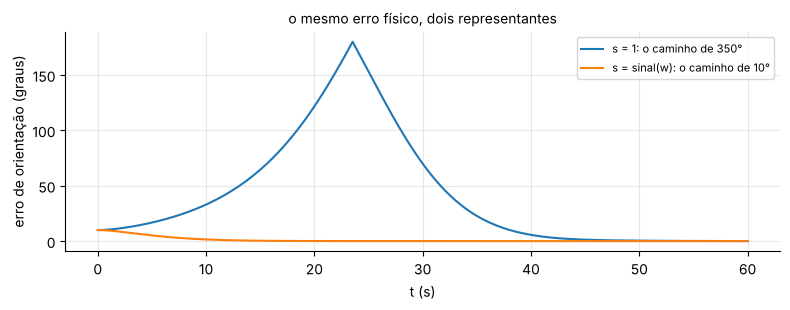

In [2]:
q10 = qexp(np.radians(10) * np.array([1, 2, 2]) / 3)
r_sem = simula(-q10, "sem"); r_sin = simula(-q10, "sinal")
for nome, r_ in [("s = 1 (sem escolher o sinal)", r_sem), ("s = sinal(w_e)", r_sin)]:
    print(f"{nome:30s}: girou {r_['giro']:6.1f}° no total;  impulso de torque {r_['impulso']:5.2f} N·m·s;  erro final {r_['ang'][-1]:.1e}°")
confere("as duas chegam à orientação desejada", [r_sem["ang"][-1] < 0.1, r_sin["ang"][-1] < 0.1], [True, True])
confere("sem o sinal, o satélite dá quase uma volta inteira (350°)", r_sem["giro"], 350, tol=5)
confere("com o sinal, gira só os 10°", r_sin["giro"], 10, tol=0.5)

t = np.arange(len(r_sem["ang"])) * h
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(t, r_sem["ang"], label="s = 1: o caminho de 350°"); ax.plot(t, r_sin["ang"], label="s = sinal(w): o caminho de 10°")
ax.set_xlabel("t (s)"); ax.set_ylabel("erro de orientação (graus)"); ax.legend(fontsize=8)
ax.set_title("o mesmo erro físico, dois representantes", fontsize=10); plt.tight_layout(); plt.show()

Repare na curva de $s=1$: o erro **cresce** de 10° até 180° antes de diminuir. O controlador acha que está a 350° do alvo e vai na direção que diminui esse número.

## 2. Perto de 180°: o chaveamento

Agora o satélite começa a 179,9° do alvo, e o sensor tem ruído de 2° por eixo. Com $s=\mathrm{sinal}(w_e)$, o sinal troca toda vez que o ruído faz $w_e$ mudar de sinal. Com histerese ($\delta=0{,}1$, ou seja, uns 11° além de 180°), o controlador escolhe um lado e só muda de ideia se o erro passar claramente para o outro.

            trocas de sinal do torque     tempo até o erro cair abaixo de 90°


sinal     :   [64, 43, 84, 61, 47]            [7.29 6.9  7.72 7.34 7.14] s


histerese :   [0, 0, 0, 0, 0]            [6.32 6.32 6.32 6.31 6.32] s
OK   com o sinal simples, o torque chaveia dezenas de vezes:  diferença máxima = 0.00e+00
OK   com histerese, não chaveia nenhuma vez:  diferença máxima = 0.00e+00
OK   e sai de perto de 180° mais cedo, em todos os ensaios:  diferença máxima = 0.00e+00


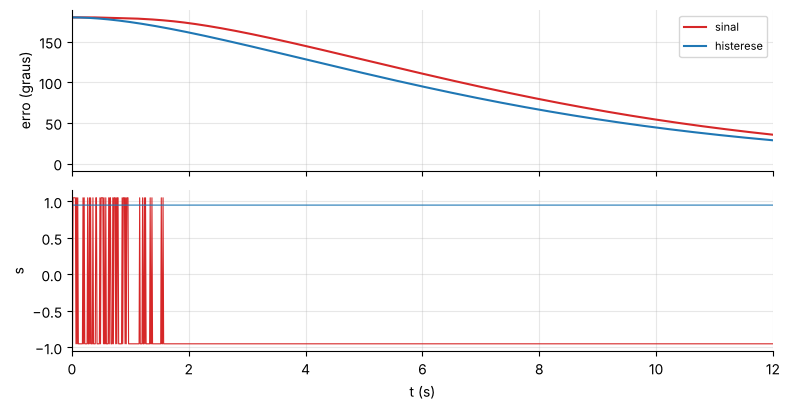

In [3]:
q180 = qexp(np.radians(179.9) * np.array([0, 0, 1.0]))
print("            trocas de sinal do torque     tempo até o erro cair abaixo de 90°")
res = {}
for modo in ["sinal", "histerese"]:
    res[modo] = [simula(q180, modo, T=30.0, sig=np.radians(2), semente=s_) for s_ in range(5)]
    tr = [r_["trocas"] for r_ in res[modo]]; t90 = [np.argmax(r_["ang"] < 90) * h for r_ in res[modo]]
    print(f"{modo:10s}:   {tr}            {np.round(t90, 2)} s")
confere("com o sinal simples, o torque chaveia dezenas de vezes", min(r_["trocas"] for r_ in res["sinal"]) > 20, True)
confere("com histerese, não chaveia nenhuma vez", max(r_["trocas"] for r_ in res["histerese"]), 0)
confere("e sai de perto de 180° mais cedo, em todos os ensaios",
        all(np.argmax(a_["ang"] < 90) > np.argmax(b_["ang"] < 90) for a_, b_ in zip(res["sinal"], res["histerese"])), True)

fig, axs = plt.subplots(2, 1, figsize=(8, 4.2), sharex=True)
t = np.arange(len(res["sinal"][0]["ang"])) * h
for modo, cor in [("sinal", "C3"), ("histerese", "C0")]:
    axs[0].plot(t, res[modo][0]["ang"], color=cor, label=modo)
    axs[1].plot(t, res[modo][0]["s"] + (0.05 if modo == "sinal" else -0.05), color=cor, lw=0.8)
axs[0].set_ylabel("erro (graus)"); axs[0].legend(fontsize=8); axs[0].set_xlim(0, 12)
axs[1].set_ylabel("s"); axs[1].set_xlabel("t (s)")
plt.tight_layout(); plt.show()

**Leitura.** O mesmo erro físico de 10° leva o controlador sem escolha de sinal a girar o satélite 350°, gastando 17 vezes mais impulso de torque. Não é um defeito de sintonia: é a dupla cobertura. Uma função contínua de $q$ não consegue distinguir $q$ de $-q$ e, ao mesmo tempo, mandar os dois pelo caminho curto. Escolher o sinal resolve isso, mas cria uma **descontinuidade** em 180°, e o ruído de medida faz o torque chavear de 43 a 84 vezes nos primeiros segundos; o satélite demora mais para sair de perto de 180° porque o controlador fica indeciso. Com histerese, o sinal não troca nenhuma vez, e o satélite sai mais cedo. O preço é que, a até uns 11° além de 180°, ele pode escolher o caminho um pouco mais longo. Mayhew, Sanfelice e Teel mostraram que nenhum controlador contínuo estabiliza globalmente uma orientação em $SO(3)$ de forma robusta a ruído: a histerese, que é um controlador **híbrido**, é a saída.

## Exercícios

1. **O tamanho da margem.** Varie $\delta$ de 0,01 a 0,5. Com $\delta$ pequeno, o chaveamento volta? Com $\delta$ grande, quanto caminho a mais o satélite pode percorrer, no pior caso?
2. **Um satélite girando.** Comece com o erro de 10° mas com uma velocidade angular inicial de 5 °/s, afastando-se do alvo. A escolha do sinal pela parte escalar continua boa? Pesquise a variante que escolhe o sinal pela "energia" $k_p(1-s\,w_e)+\tfrac12\boldsymbol\omega^\top I\boldsymbol\omega$.
3. **Atuadores reais.** Rodas de reação saturam (aqui, por exemplo, em 0,1 N·m). Sature o torque e repita a seção 1. Quanto tempo o satélite leva no caminho de 350°?